In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
os.makedirs("output", exist_ok=True)

# Load the training dataset
df = pd.read_csv("train.csv")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [2]:
print("Dataset information:")
df.info()

print("\nDescriptive statistics:")
display(df.describe().T)

print("\nMissing values in the top 20 columns:")
missing = df.isnull().sum().sort_values(ascending=False)
display(missing[missing > 0].head(20))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget variable summary:")
display(df["SalePrice"].describe())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0



Missing values in the top 20 columns:


PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


Duplicate rows: 0

Target variable summary:


count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

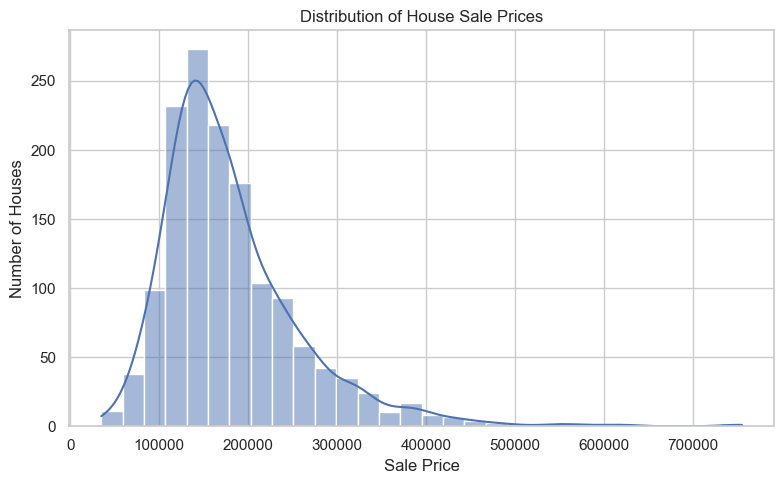

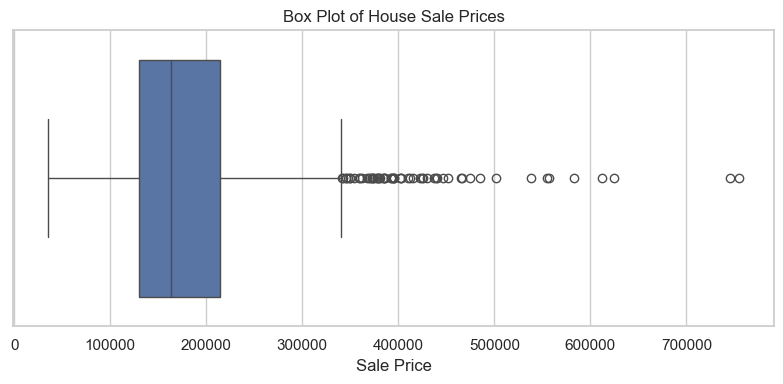

In [3]:
plt.figure(figsize=(8, 5))
sns.histplot(df["SalePrice"], kde=True, bins=30)
plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Number of Houses")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 4))
sns.boxplot(x=df["SalePrice"])
plt.title("Box Plot of House Sale Prices")
plt.xlabel("Sale Price")
plt.tight_layout()
plt.show()

In [4]:
features = [
    "GrLivArea",
    "OverallQual",
    "TotalBsmtSF",
    "GarageCars",
    "YearBuilt",
    "FullBath",
    "Neighborhood",
    "KitchenQual"
]

target = "SalePrice"

X = df[features].copy()
y = df[target].copy()

print("Selected features:", features)
print("Target:", target)
print("Feature matrix shape:", X.shape)

Selected features: ['GrLivArea', 'OverallQual', 'TotalBsmtSF', 'GarageCars', 'YearBuilt', 'FullBath', 'Neighborhood', 'KitchenQual']
Target: SalePrice
Feature matrix shape: (1460, 8)


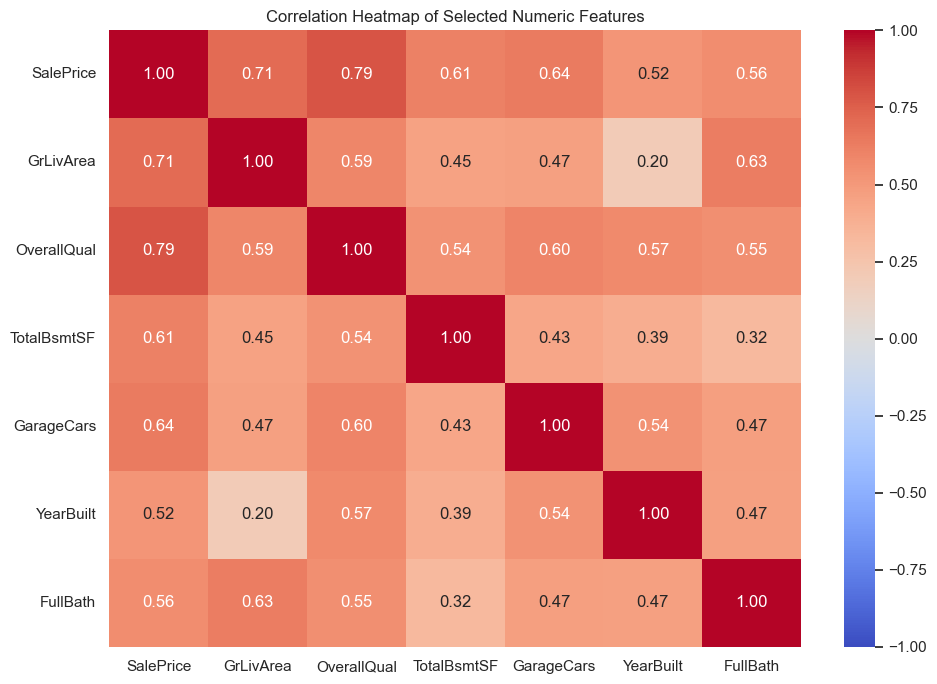

Correlation with SalePrice:


OverallQual    0.790982
GrLivArea      0.708624
GarageCars     0.640409
TotalBsmtSF    0.613581
FullBath       0.560664
YearBuilt      0.522897
Name: SalePrice, dtype: float64

In [5]:
numeric_columns = [
    "SalePrice",
    "GrLivArea",
    "OverallQual",
    "TotalBsmtSF",
    "GarageCars",
    "YearBuilt",
    "FullBath"
]

correlation = df[numeric_columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title("Correlation Heatmap of Selected Numeric Features")
plt.tight_layout()
plt.show()

print("Correlation with SalePrice:")
display(
    correlation["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 1168
Testing records: 292


In [7]:
numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['GrLivArea', 'OverallQual', 'TotalBsmtSF', 'GarageCars', 'YearBuilt', 'FullBath']
Categorical features: ['Neighborhood', 'KitchenQual']


C:\Users\gopik\AppData\Local\Temp\ipykernel_17572\2168621887.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


In [8]:
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [9]:
y_pred = linear_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Squared Error (MSE): ${mse:,.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:,.2f}")
print(f"R² Score: {r2:.4f}")

Mean Squared Error (MSE): $1,211,776,003.01
Root Mean Squared Error (RMSE): $34,810.57
R² Score: 0.8420


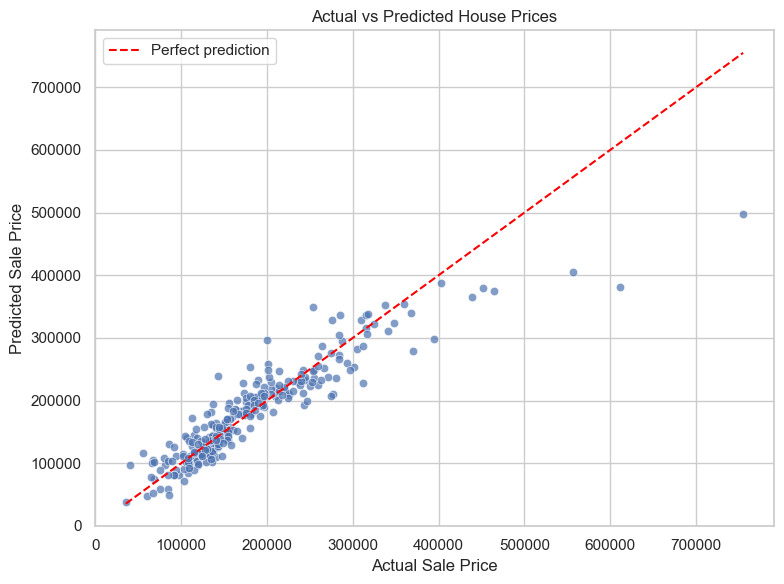

In [10]:
plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test, y=y_pred, alpha=0.7)

# Ideal predictions lie on this diagonal
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    linestyle="--",
    color="red",
    label="Perfect prediction"
)

plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.tight_layout()
plt.show()

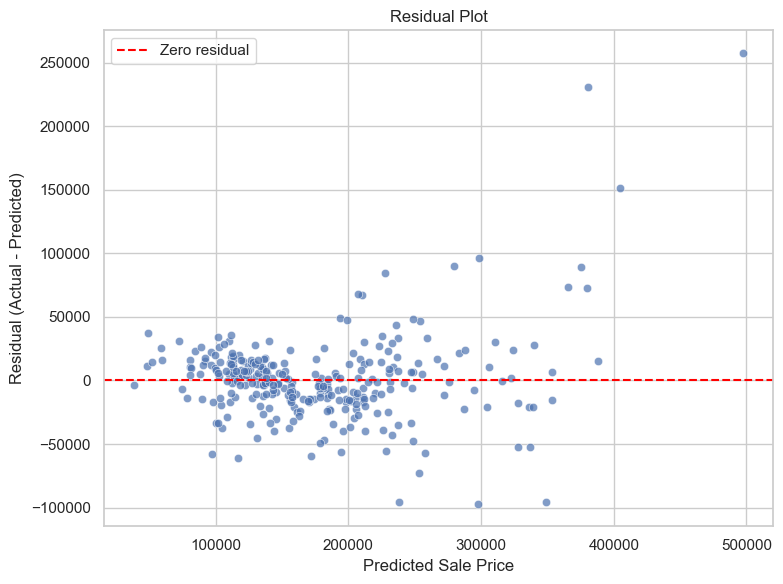

In [11]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.7)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    label="Zero residual"
)

plt.xlabel("Predicted Sale Price")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.legend()
plt.tight_layout()
plt.show()

Largest coefficients by absolute magnitude:


,Feature,Coefficient,AbsoluteCoefficient
21,categorical__Neighborhood_NoRidge,51610.568438,51610.568438
28,categorical__Neighborhood_StoneBr,40678.444580,40678.444580
31,categorical__KitchenQual_Ex,38212.330689,38212.330689
8,categorical__Neighborhood_BrDale,-36687.375472,36687.375472
30,categorical__Neighborhood_Veenker,35222.197338,35222.197338
22,categorical__Neighborhood_NridgHt,32985.830880,32985.830880
10,categorical__Neighborhood_ClearCr,28178.110524,28178.110524
6,categorical__Neighborhood_Blmngtn,-23334.391660,23334.391660
12,categorical__Neighborhood_Crawfor,22389.412819,22389.412819
16,categorical__Neighborhood_MeadowV,-21808.469322,21808.469322


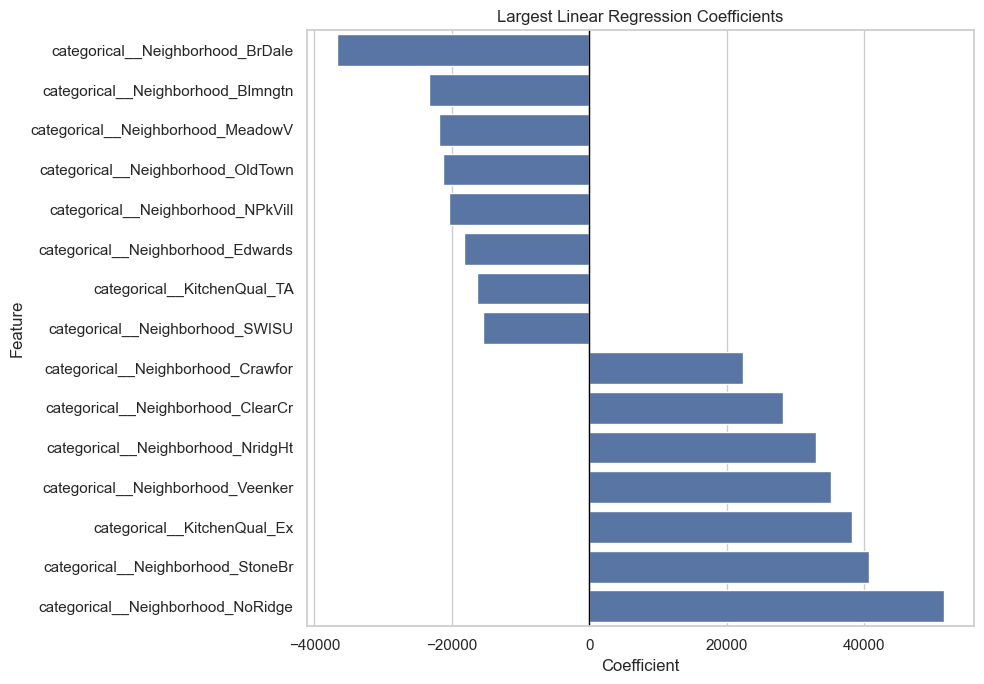

In [12]:
# Retrieve the trained preprocessing and regression steps
fitted_preprocessor = linear_model.named_steps["preprocessor"]
fitted_regressor = linear_model.named_steps["regressor"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_regressor.coef_

coef_df = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

coef_df["AbsoluteCoefficient"] = coef_df["Coefficient"].abs()
coef_df = coef_df.sort_values(
    "AbsoluteCoefficient",
    ascending=False
)

print("Largest coefficients by absolute magnitude:")
display(coef_df.head(15))

# Plot the 15 largest absolute coefficients
top_coef = coef_df.head(15).sort_values("Coefficient")

plt.figure(figsize=(10, 7))
sns.barplot(
    data=top_coef,
    x="Coefficient",
    y="Feature"
)
plt.axvline(0, color="black", linewidth=1)
plt.title("Largest Linear Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [13]:
ridge_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", Ridge(alpha=10.0))
])

ridge_model.fit(X_train, y_train)
ridge_pred = ridge_model.predict(X_test)

results = pd.DataFrame({
    "Model": ["Linear Regression", "Ridge Regression"],
    "MSE": [
        mean_squared_error(y_test, y_pred),
        mean_squared_error(y_test, ridge_pred)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred)),
        np.sqrt(mean_squared_error(y_test, ridge_pred))
    ],
    "R2": [
        r2_score(y_test, y_pred),
        r2_score(y_test, ridge_pred)
    ]
})

display(results.round(4))

,Model,MSE,RMSE,R2
0,Linear Regression,1.211776e+09,34810.5731,0.8420
1,Ridge Regression,1.377999e+09,37121.4052,0.8203


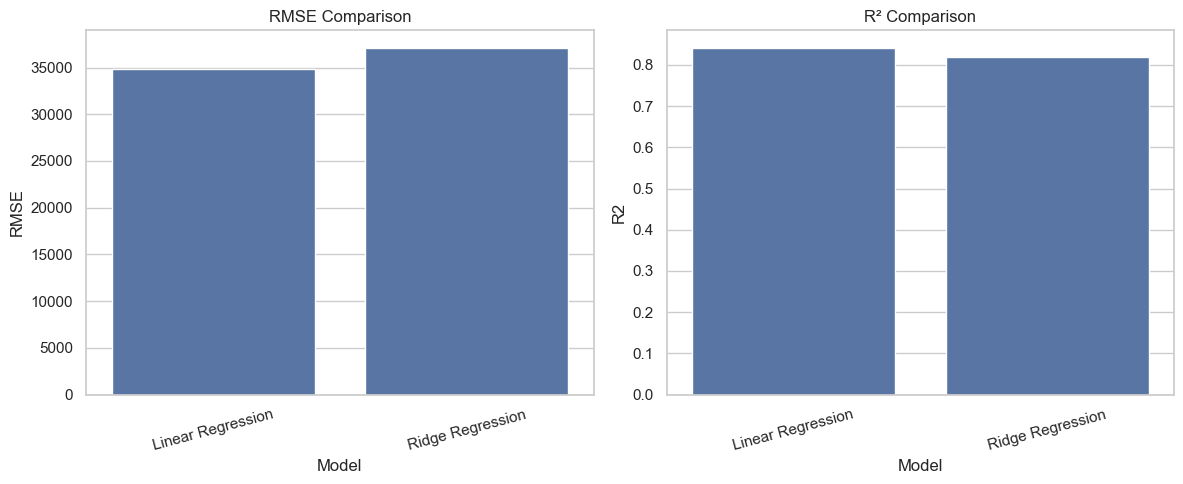

In [14]:
results_melted = results.melt(
    id_vars="Model",
    value_vars=["RMSE", "R2"],
    var_name="Metric",
    value_name="Score"
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=results,
    x="Model",
    y="RMSE",
    ax=axes[0]
)
axes[0].set_title("RMSE Comparison")
axes[0].tick_params(axis="x", rotation=15)

sns.barplot(
    data=results,
    x="Model",
    y="R2",
    ax=axes[1]
)
axes[1].set_title("R² Comparison")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

In [15]:
# Save test predictions
predictions = pd.DataFrame({
    "ActualPrice": y_test,
    "LinearRegressionPrediction": y_pred,
    "Residual": y_test - y_pred
})

predictions.to_csv(
    "output/house_price_predictions.csv",
    index=False
)

# Save evaluation metrics
results.to_csv(
    "output/model_comparison.csv",
    index=False
)

# Save coefficient analysis
coef_df.to_csv(
    "output/linear_regression_coefficients.csv",
    index=False
)

print("Results saved in the output folder.")

Results saved in the output folder.
